# Linear system (Section 5.1)

Consider a linear system with output $y(t;\beta)=\beta_1e^{-a_1t}+\beta_2e^{-a_2t}$.

The reduced model output is $\widehat y(t;\alpha)=\alpha e^{-a_rt}$. 

Here, we show the application of our method to run MCMC on the detailed model by learning the compatible parameter regions from the reduced model.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "hierarch_inf").is_dir()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, quad
from scipy.optimize import minimize_scalar, brentq
from scipy.stats import norm, chi2
from hierarch_inf import py_inference, build_behavioral_gp_from_reduced_posterior

## Thresholds and hyperarameter choices

The model likelihood is the integrated squared error with a scaling factor $s_L$. We set the data-fit tolerance $\eta$ from the known noise level and a prescribed confidence level. We set $\epsilon=\eta+q_\gamma$, where $q_\gamma$ is the
$\gamma$-quantile of reduced model posterior distance from the observations.

For this linear example the quantile is obtained from the closed-form Gaussian posterior. This is used for guided parameter inference.

In [2]:
RANDOM_SEED = 42
a1, a2, ar = 1.0, 2.0, 1.5
T, N_TIMEPOINTS = 10.0, 1001
NOISE_STD = 0.02 
LIKELIHOOD_SCALE = 0.1 #s_L
NOISE_CONFIDENCE = 0.95
N_INITIAL_CONDITIONS, TRUE_INDEX = 200, 99 # the true index is the chosen ground truth.

DETAILED_PRIOR_BOUNDS = (0.0, 2.0)
NWALKERS, NSTEPS, BURN = 16, 1000, 200
gamma, zeta = 0.80, 0.95  # 95% GP probability of behavioral compatibility
N_INITIAL_GP, N_MPM_STEPS = 6, 100
N_INTEGRATION_POINTS, N_ACQUISITION_CANDIDATES = 2000, 200
MAX_REDUCED_SAMPLES = None

BASELINE_COLOR, GUIDED_COLOR = "#174a7e", "#c45113"


## Synthetic data and model outputs

Noise-derived data-fit tolerance eta: 0.06559622637152543
Ground-truth initial condition: [0.96189766 0.64248328]


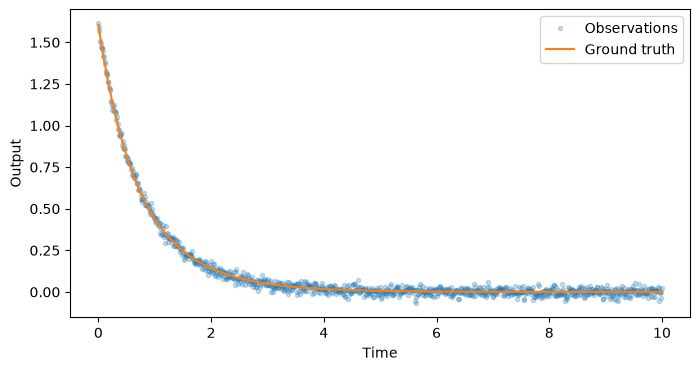

In [3]:
RANDOM_SEED = 42
NOISE_STD = 0.02
NOISE_CONFIDENCE = 0.95
N_INITIAL_CONDITIONS, TRUE_INDEX = 200, 99

rng = np.random.default_rng(RANDOM_SEED)
beta1 = rng.random(N_INITIAL_CONDITIONS)
beta2 = rng.random(N_INITIAL_CONDITIONS)
beta_true = np.array([beta1[TRUE_INDEX], beta2[TRUE_INDEX]])
tp = np.linspace(0.0, T, N_TIMEPOINTS)
time_intervals = np.diff(tp)
quadrature_weights = np.r_[time_intervals[0]/2,
    (time_intervals[:-1]+time_intervals[1:])/2, time_intervals[-1]/2]
# With independent Gaussian noise, sum((noise/NOISE_STD)**2) is chi-squared.
eta = NOISE_STD * np.sqrt(
    quadrature_weights.max() * chi2.ppf(NOISE_CONFIDENCE, len(tp))
)
print("Noise-derived data-fit tolerance eta:", eta)
phi = np.column_stack([np.exp(-a1 * tp), np.exp(-a2 * tp)])
psi = np.exp(-ar * tp)
y_true = phi @ beta_true
y_obs = y_true + rng.normal(0.0, NOISE_STD, size=tp.size)
data = {"t": tp, "y_obs": y_obs}

def detailed_trajectory_fn(parameters):
    """Evaluate the two-state linear output at the supplied parameters."""
    return phi @ np.array([parameters["beta1"], parameters["beta2"]])

def reduced_trajectory_fn(parameters):
    """Evaluate the one-state reduced output at the supplied parameter."""
    return parameters["alpha"] * psi

print("Ground-truth initial condition:", beta_true)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tp, y_obs, ".", alpha=0.25, label="Observations")
ax.plot(tp, y_true, label="Ground truth")
ax.set(xlabel="Time", ylabel="Output")
ax.legend()
plt.show()

## Verify the optimal reduced initial condition

With $Q_T=\int\phi\phi^Tdt$, $q=\int\phi\psi\,dt$, and
$r=\int\psi^2dt$, the projection is $\alpha^*(\beta)=q^T\beta/r$ and
the minimum squared distance is $\beta^TE_T\beta$, where
$E_T=Q_T-qq^T/r$. Numerical quadrature and scalar optimization provide
independent checks at $(1,0)$, $(0,1)$, and the ground truth.

In [4]:
def exponential_integral(rate):
    """Integrate the decaying exponential over the finite observation horizon."""
    return -np.expm1(-rate * T) / rate

QT = np.array([[exponential_integral(2 * a1), exponential_integral(a1 + a2)],
               [exponential_integral(a1 + a2), exponential_integral(2 * a2)]])
q = np.array([exponential_integral(a1 + ar), exponential_integral(a2 + ar)])
r = exponential_integral(2 * ar)
ET = QT - np.outer(q, q) / r

for beta in (np.array([1.0, 0.0]), np.array([0.0, 1.0]), beta_true):
    alpha_star = q @ beta / r
    squared_distance = beta @ ET @ beta
    def objective(alpha):
        """Evaluate the reduced-parameter projection objective."""
        return quad(lambda t: (beta[0] * np.exp(-a1*t) + beta[1] * np.exp(-a2*t)
                               - alpha * np.exp(-ar*t))**2, 0.0, T)[0]
    numerical = minimize_scalar(objective)
    np.testing.assert_allclose(numerical.x, alpha_star, atol=1e-7)
    np.testing.assert_allclose(numerical.fun, squared_distance, atol=1e-10)
    print(f"beta={beta}; alpha*={alpha_star:.6f}; minimum squared L2={squared_distance:.6f}")

beta=[1. 0.]; alpha*=1.200000; minimum squared L2=0.020000
beta=[0. 1.]; alpha*=0.857143; minimum squared L2=0.005102
beta=[0.96189766 0.64248328]; alpha*=1.704977; minimum squared L2=0.008839


## 1. Baseline detailed-model inference

For either model output $g$, define the misfit likelihood
$\log L(\theta)=-d_T^2(g(\theta),\bar y)/(2s_L^2)+\mathrm{const}$, with
$d_T^2=\int_0^T(g(t;\theta)-\bar y(t))^2\,dt$.



In [5]:
NWALKERS = 16
NSTEPS = 1000
BURN = 200
RANDOM_SEED = 42

detailed_param_names = ["beta1", "beta2"]
detailed_lower_bounds = np.full(2, DETAILED_PRIOR_BOUNDS[0])
detailed_upper_bounds = np.full(2, DETAILED_PRIOR_BOUNDS[1])
detailed_prior = {name: ["uniform", lower, upper]
                  for name, lower, upper in zip(
                      detailed_param_names, detailed_lower_bounds, detailed_upper_bounds)}

def detailed_log_likelihood(parameters, observations):
    """Evaluate the detailed linear model likelihood against the observations."""
    residual = detailed_trajectory_fn(parameters) - observations["y_obs"]
    return -0.5 * trapezoid(residual**2, x=observations["t"]) / LIKELIHOOD_SCALE**2

detailed_result = py_inference(
    likelihood=detailed_log_likelihood, data=data,
    params_to_estimate=detailed_param_names, prior=detailed_prior,
    nwalkers=NWALKERS, nsteps=NSTEPS, discard=BURN, random_seed=RANDOM_SEED,
)

## 2. Reduced-model inference

Fit the reduced model to the same `y_obs` used in the detailed fit.


In [6]:
NWALKERS = 16
NSTEPS = 1000
BURN = 200
RANDOM_SEED = 42

reduced_param_names = ["alpha"]
reduced_prior = {"alpha": ["normal", 1.0, 0.5]}

def reduced_log_likelihood(parameters, observations):
    """Evaluate the reduced linear model likelihood against the observations."""
    residual = reduced_trajectory_fn(parameters) - observations["y_obs"]
    return -0.5 * trapezoid(residual**2, x=observations["t"]) / LIKELIHOOD_SCALE**2

reduced_result = py_inference(
    likelihood=reduced_log_likelihood, data=data,
    params_to_estimate=reduced_param_names, prior=reduced_prior,
    nwalkers=NWALKERS, nsteps=NSTEPS, discard=BURN, random_seed=RANDOM_SEED,
)

# The reduced posterior is analytically Gaussian for this linear likelihood.
r_grid = trapezoid(psi**2, x=tp)
reduced_variance = 1.0 / (r_grid / LIKELIHOOD_SCALE**2 + 1.0 / 0.5**2)
reduced_mean = reduced_variance * (trapezoid(psi*y_obs, x=tp) / LIKELIHOOD_SCALE**2 + 1.0 / 0.5**2)
print("Analytical reduced posterior mean/std:", reduced_mean, np.sqrt(reduced_variance))
print("MCMC reduced posterior mean/std:", reduced_result.flat_samples.mean(), reduced_result.flat_samples.std())

alpha_observed = trapezoid(psi*y_obs, x=tp) / r_grid
minimum_reduced_data_distance_squared = trapezoid((alpha_observed*psi-y_obs)**2, x=tp)

def reduced_posterior_fit_mass(threshold):
    """Evaluate reduced-posterior mass within the data discrepancy threshold."""
    budget = threshold**2 - minimum_reduced_data_distance_squared
    if threshold < 0.0 or budget < 0.0:
        return 0.0
    radius = np.sqrt(budget / r_grid)
    return float(norm.cdf(alpha_observed+radius, reduced_mean, np.sqrt(reduced_variance)) -
                 norm.cdf(alpha_observed-radius, reduced_mean, np.sqrt(reduced_variance)))

# Choose the compatibility tolerance by the prescribed posterior-quantile rule.
lower_quantile = np.sqrt(minimum_reduced_data_distance_squared)
upper_quantile = max(lower_quantile+1.0, 1.0)
while reduced_posterior_fit_mass(upper_quantile) < gamma:
    upper_quantile *= 2.0
reduced_data_gamma_quantile = brentq(
    lambda threshold: reduced_posterior_fit_mass(threshold)-gamma,
    lower_quantile, upper_quantile, xtol=1e-12,
)
epsilon = eta + reduced_data_gamma_quantile
analytical_fit_mass = reduced_posterior_fit_mass(epsilon-eta)
print("Reduced-posterior discrepancy gamma-quantile:", reduced_data_gamma_quantile)
print("Derived compatibility tolerance epsilon:", epsilon)
retention_condition_satisfied = analytical_fit_mass >= gamma - 1e-10
beta_observed = np.linalg.solve(trapezoid(phi[:, :, None]*phi[:, None, :], x=tp, axis=0),
                               trapezoid(phi*y_obs[:, None], x=tp, axis=0))
minimum_detailed_data_distance = np.sqrt(trapezoid((phi@beta_observed-y_obs)**2, x=tp))
print("Minimum detailed / reduced data L2:", minimum_detailed_data_distance,
      np.sqrt(minimum_reduced_data_distance_squared))
print("Analytical reduced-posterior fit mass at epsilon-eta:", analytical_fit_mass)
print("Exact retention condition satisfied:", retention_condition_satisfied)
print("Detailed data-fit region nonempty:", minimum_detailed_data_distance <= eta)


Analytical reduced posterior mean/std: 1.6267785425593304 0.1636579382324549
MCMC reduced posterior mean/std: 1.6245017231527623 0.1640924934318149
Reduced-posterior discrepancy gamma-quantile: 0.17474828364287937
Derived compatibility tolerance epsilon: 0.2403445100144048
Minimum detailed / reduced data L2: 0.06397372736262864 0.11248052377412503
Analytical reduced-posterior fit mass at epsilon-eta: 0.8
Exact retention condition satisfied: True
Detailed data-fit region nonempty: True


## 3. Learn $b_\epsilon(\beta)-\gamma$ with GP-MPM

The behavioral support
$b_\epsilon(\beta)=\widehat\pi\{\,\alpha:
d_T(y(\beta),\widehat y(\alpha))\le\epsilon\,\}$
is the probability of compatible reduced trajectories under the reduced
posterior. 

In [7]:
zeta = 0.95
N_INITIAL_GP = 6
N_MPM_STEPS = 100
N_INTEGRATION_POINTS = 2000
N_ACQUISITION_CANDIDATES = 200
MAX_REDUCED_SAMPLES = None
RANDOM_SEED = 42

def l2_discrepancy(reference_trajectories, candidate_trajectory, condition_weights=None):
    """Compute the finite-horizon L2 discrepancy between model outputs."""
    reference = np.asarray(reference_trajectories)
    candidate = np.asarray(candidate_trajectory)
    squared = trapezoid((reference - candidate[None, :, :])**2, x=tp, axis=-1)
    weights = np.ones(squared.shape[1]) if condition_weights is None else np.asarray(condition_weights)
    return np.sqrt(np.maximum(squared @ weights, 0.0))

gp_result = build_behavioral_gp_from_reduced_posterior(
    reduced_result.flat_samples,
    reduced_param_names=reduced_param_names, reduced_trajectory_fn=reduced_trajectory_fn,
    detailed_param_names=detailed_param_names,
    detailed_lower_bounds=detailed_lower_bounds, detailed_upper_bounds=detailed_upper_bounds,
    detailed_trajectory_fn=detailed_trajectory_fn, observed_trajectory=y_obs,
    epsilon=epsilon, posterior_level_set_boundary=gamma,
    data_discrepancy_threshold=eta, gp_screening_level=zeta,
    discrepancy_fn=l2_discrepancy, detailed_log_scale=False,
    n_initial=N_INITIAL_GP, n_mpm_steps=N_MPM_STEPS,
    n_integration_points=N_INTEGRATION_POINTS,
    n_acquisition_candidates=N_ACQUISITION_CANDIDATES,
    max_reduced_samples=MAX_REDUCED_SAMPLES, random_seed=RANDOM_SEED,
)
print("Empirical reduced-posterior fit mass:", gp_result.reduced_posterior_fit_mass)
print("Empirical retention condition satisfied:", gamma <= gp_result.reduced_posterior_fit_mass)

c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 21 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_resul

Empirical reduced-posterior fit mass: 0.79703125
Empirical retention condition satisfied: False


c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


## 4. Behaviorally guided detailed-model inference

Use the trained GP to filter proposals before the detailed likelihood. The GP filtering level is $\zeta=0.95$. A proposal passes only when its
GP posterior probability of satisfying the learned compatibility criterion
exceeds this level. 

In [8]:
NWALKERS = 16
NSTEPS = 1000
BURN = 200
RANDOM_SEED = 42

detailed_gp_result = py_inference(
    likelihood=detailed_log_likelihood, data=data,
    params_to_estimate=detailed_param_names, prior=detailed_prior,
    custom_joint_prior=gp_result.custom_joint_prior,
    nwalkers=NWALKERS, nsteps=NSTEPS, discard=BURN, random_seed=RANDOM_SEED,
)

## Behavioral compatibility and MCMC sampling performance

Here $\theta=(\beta_1,\beta_2)^T$. We show the empirical estimate
$\widehat b_{\epsilon,M}(\theta)$ and the behavioral compatibility region
$\{\theta:\widehat b_{\epsilon,M}(\theta)\ge\gamma\}$, bounded by the burgundy
$\widehat b_{\epsilon,M}(\theta)=\gamma$ contour. Values below $\gamma$ lie
outside this region. 

We also visualize the trained GP filtering probability $p_K(\theta)$ and
baseline/GP-guided MCMC states across the full shared $[0,2]^2$ prior domain.

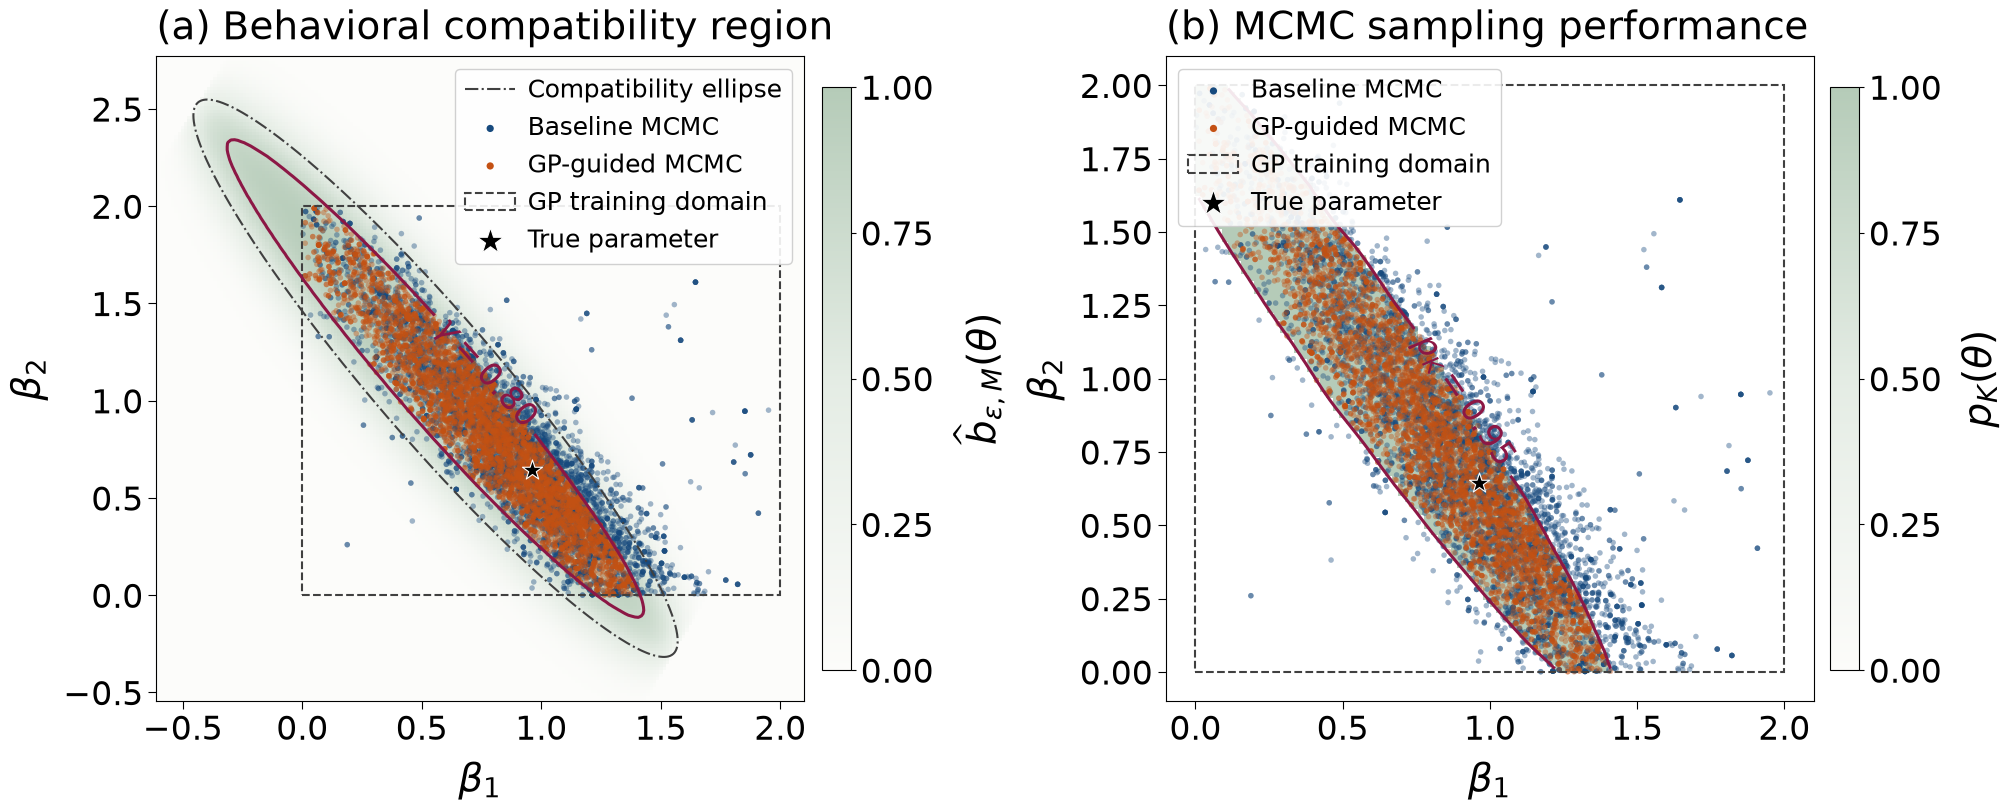

Ground-truth empirical / analytical compatibility probability: [0.96742187] [0.96636491]
Minimum exact compatibility probability on data-fit grid: 0.9555010211034841
In-domain data-fit grid points / rejected by GP: 15 0
Unrestricted data-fit coordinate ranges: [0.89621474 0.55771607] [1.01923438 0.73168341]
Data-fit region extends beyond GP training domain: False
Baseline draws outside learned GP acceptance region: 0.2359375
Baseline draws with empirical b_epsilon below gamma: 0.2315625
Guided draws outside learned GP acceptance region: 0.0
Prior-domain grid fraction allowed by the GP filter: 0.1818
Baseline warm-up states outside learned GP acceptance region: 924 of 3200


In [9]:
BASELINE_COLOR, GUIDED_COLOR = "#174a7e", "#c45113"
PLOT_SAMPLE_SEED = 42

SUPPORT_MAP_POINTS = 100
JOINT_MAX_POINTS = 1500
JOINT_POINT_ALPHA = 0.40
TICK_FONT_SIZE = 24
AXIS_FONT_SIZE = 28
LEGEND_FONT_SIZE = 18
GAMMA_FONT_SIZE = 24
GAMMA_LABEL_POSITION = None
PAPER_FIGSIZE = (20, 8)
SUPPORT_COLORS = ["#fcfcfa", "#e4ece4", "#b5cbb8"]

from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

samples_baseline = detailed_result.flat_samples
samples_guided = detailed_gp_result.flat_samples
alpha_samples = np.sort(gp_result.reduced_posterior_samples[:, 0])
q_grid = trapezoid(phi * psi[:, None], x=tp, axis=0)
Q_grid = trapezoid(phi[:, :, None] * phi[:, None, :], x=tp, axis=0)
E_grid = Q_grid - np.outer(q_grid, q_grid) / r_grid

def support_values(beta, *, analytic=False):
    """Evaluate empirical support from the reduced-posterior trajectories."""
    beta = np.atleast_2d(beta)
    center = beta @ q_grid / r_grid
    budget = epsilon**2 - np.einsum("ni,ij,nj->n", beta, E_grid, beta)
    radius = np.sqrt(np.maximum(budget, 0.0) / r_grid)
    if analytic:
        support = norm.cdf(center+radius, reduced_mean, np.sqrt(reduced_variance)) - norm.cdf(
            center-radius, reduced_mean, np.sqrt(reduced_variance))
    else:
        support = (np.searchsorted(alpha_samples, center+radius, side="right") -
                   np.searchsorted(alpha_samples, center-radius, side="left")) / len(alpha_samples)
    return np.where(budget >= 0.0, support, 0.0)

# Exact compatibility ellipse at a fixed reduced posterior parameter.
inverse_Q = np.linalg.inv(Q_grid)
ellipse_center = reduced_mean * (inverse_Q @ q_grid)
ellipse_budget = epsilon**2 - reduced_mean**2 * (r_grid-q_grid @ inverse_Q @ q_grid)
if ellipse_budget <= 0:
    raise ValueError("No compatibility ellipse at the selected reduced parameter.")
eigenvalues, eigenvectors = np.linalg.eigh(Q_grid)
angle = np.linspace(0.0, 2*np.pi, 1001)
ellipse_points = ellipse_center + (
    np.column_stack([np.cos(angle), np.sin(angle)]) *
    np.sqrt(ellipse_budget/eigenvalues)
) @ eigenvectors.T

# Any compatible interval with empirical mass >= gamma intersects this
# central posterior interval. These bounds contain its full level set.
alpha_bounds = np.quantile(alpha_samples, [gamma/4, 1-gamma/4])
center_bounds = alpha_bounds[:, None] * (inverse_Q @ q_grid)[None, :]
coordinate_radius = epsilon * np.sqrt(np.diag(inverse_Q))
pool = np.vstack([center_bounds-coordinate_radius, center_bounds+coordinate_radius,
                  ellipse_points, samples_baseline, samples_guided, beta_true,
                  detailed_lower_bounds, detailed_upper_bounds])
lo, hi = pool.min(axis=0), pool.max(axis=0)
padding = 0.04 * np.maximum(hi-lo, 1e-6)
overview_lo, overview_hi = lo-padding, hi+padding
overview_x, overview_y = np.meshgrid(
    np.linspace(overview_lo[0], overview_hi[0], 2*SUPPORT_MAP_POINTS),
    np.linspace(overview_lo[1], overview_hi[1], 2*SUPPORT_MAP_POINTS))
overview_grid = np.column_stack([overview_x.ravel(), overview_y.ravel()])
overview_support = support_values(overview_grid).reshape(overview_x.shape)

# The acceptance panel uses the trained GP actually used by guided MCMC.
padding = 0.05 * (detailed_upper_bounds-detailed_lower_bounds)
plot_lo = detailed_lower_bounds-padding
plot_hi = detailed_upper_bounds+padding
xx, yy = np.meshgrid(np.linspace(plot_lo[0], plot_hi[0], SUPPORT_MAP_POINTS),
                     np.linspace(plot_lo[1], plot_hi[1], SUPPORT_MAP_POINTS))
grid = np.column_stack([xx.ravel(), yy.ravel()])
inside_domain = np.all((grid >= detailed_lower_bounds) &
                       (grid <= detailed_upper_bounds), axis=1)
screen_probability = np.full(len(grid), np.nan)
screen_probability[inside_domain] = gp_result.validity_model.retained_probability(
    grid[inside_domain])
screen_probability = np.ma.masked_invalid(screen_probability.reshape(xx.shape))
# Colour only the GP-accepted region; rejected points remain uncoloured.
accepted_screen_probability = np.ma.masked_where(
    screen_probability <= zeta, screen_probability)
# Contour the equivalent Gaussian margin to avoid probability saturation.
gp_mean, gp_std = gp_result.validity_model.gp.predict(
    gp_result.validity_model.parameters_to_gp(grid[inside_domain]), return_std=True)
screen_margin = np.full(len(grid), np.nan)
screen_margin[inside_domain] = gp_mean-norm.ppf(zeta)*np.maximum(gp_std, 1e-12)
screen_margin = np.ma.masked_invalid(screen_margin.reshape(xx.shape))

def label_boundary(axis, contour, level, text, lower, upper, *, upper_left=False):
    """Place a label on the plotted behavioral-support boundary."""
    segments = [segment for segment in contour.allsegs[0] if len(segment) > 1]
    if not segments:
        return
    candidates = np.vstack(segments)
    points = (candidates-lower)/(upper-lower)
    score = np.min(np.column_stack([points, 1-points]), axis=1)
    obscured = points[:, 0] < 0.50 if upper_left else points[:, 0] > 0.50
    score[obscured & (points[:, 1] > 0.60)] = -np.inf
    position = candidates[np.argmax(score)]
    if level == gamma and GAMMA_LABEL_POSITION is not None:
        position = GAMMA_LABEL_POSITION
    labels = axis.clabel(contour, fmt={level: text}, fontsize=GAMMA_FONT_SIZE,
                         inline=True, inline_spacing=8, manual=[tuple(position)])
    for label in labels:
        label.set_zorder(10)

# Keep the original colors and typography independent of other notebooks.
with plt.rc_context(rc=plt.rcParamsDefault):
    support_cmap = LinearSegmentedColormap.from_list("soft_support", SUPPORT_COLORS)
    fig, (overview_ax, acceptance_ax) = plt.subplots(
        1, 2, figsize=PAPER_FIGSIZE, constrained_layout=True)

    mesh = overview_ax.pcolormesh(
        overview_x, overview_y, overview_support, cmap=support_cmap,
        vmin=0, vmax=1, shading="auto", rasterized=True, zorder=0)
    colorbar = fig.colorbar(mesh, ax=overview_ax, pad=0.025, fraction=0.045)
    colorbar.set_label(r"$\widehat b_{\epsilon,M}(\theta)$",
                       fontsize=AXIS_FONT_SIZE, labelpad=14)
    colorbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
    if overview_support.min() < gamma < overview_support.max():
        contour = overview_ax.contour(
            overview_x, overview_y, overview_support, levels=[gamma],
            colors="#8c1745", linewidths=2.2, zorder=4)
        label_boundary(overview_ax, contour, gamma, rf"$\gamma={gamma:.2f}$",
                       overview_lo, overview_hi)
    overview_ax.plot(*ellipse_points.T, color="#404040", linestyle="-.",
                     linewidth=1.5, label="Compatibility ellipse", zorder=3)

    mesh = acceptance_ax.pcolormesh(
        xx, yy, accepted_screen_probability, cmap=support_cmap, vmin=0, vmax=1,
        shading="auto", rasterized=True, zorder=0)
    colorbar = fig.colorbar(mesh, ax=acceptance_ax, pad=0.025, fraction=0.045)
    colorbar.set_label(r"$p_K(\theta)$", fontsize=AXIS_FONT_SIZE, labelpad=14)
    colorbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
    if screen_margin.min() < 0 < screen_margin.max():
        contour = acceptance_ax.contour(
            xx, yy, screen_margin, levels=[0],
            colors="#8c1745", linewidths=2.2, zorder=4)
        if zeta > 0.99999 and np.isclose(1.0-zeta, 10.0**np.rint(np.log10(1.0-zeta)),
                                       rtol=1e-3, atol=0.0):
            tail_exponent = int(np.rint(np.log10(1.0-zeta)))
            screen_label = rf"$p_K=1-10^{{{tail_exponent}}}$"
        else:
            screen_label = rf"$p_K={zeta:.6g}$"
        label_boundary(acceptance_ax, contour, 0, screen_label,
                       plot_lo, plot_hi, upper_left=True)

    plot_rng = np.random.default_rng(PLOT_SAMPLE_SEED)
    for result, samples, color, label in [
        (detailed_result, samples_baseline, BASELINE_COLOR, "Baseline MCMC"),
        (detailed_gp_result, samples_guided, GUIDED_COLOR, "GP-guided MCMC")
    ]:
        selected = plot_rng.choice(
            len(samples), min(JOINT_MAX_POINTS, len(samples)), replace=False)
        warmup = result.chain[:BURN].reshape(-1, len(result.param_names))
        displayed_states = np.vstack([warmup, samples[selected]])
        for axis in (overview_ax, acceptance_ax):
            axis.scatter(*displayed_states.T, s=16, alpha=JOINT_POINT_ALPHA,
                         color=color, label=label, rasterized=True,
                         edgecolors="none", zorder=2)

    for axis, lower, upper, panel, location in [
        (overview_ax, overview_lo, overview_hi,
         "(a) Behavioral compatibility region", "upper right"),
        (acceptance_ax, plot_lo, plot_hi,
         "(b) MCMC sampling performance", "upper left")
    ]:
        axis.add_patch(Rectangle(
            detailed_lower_bounds, *(detailed_upper_bounds-detailed_lower_bounds),
            fill=False, linestyle="--", linewidth=1.5, edgecolor="#404040",
            label="GP training domain", zorder=3))
        axis.scatter(*beta_true, marker="*", s=230, color="black", edgecolors="white",
                     linewidths=0.8, label="True parameter", zorder=5)
        axis.set_xlim(lower[0], upper[0])
        axis.set_ylim(lower[1], upper[1])
        axis.set_xlabel(r"$\beta_1$", fontsize=AXIS_FONT_SIZE, labelpad=10)
        axis.set_ylabel(r"$\beta_2$", fontsize=AXIS_FONT_SIZE, labelpad=10)
        axis.set_title(panel, loc="left", fontweight="normal", fontsize=AXIS_FONT_SIZE, pad=12)
        axis.tick_params(axis="both", which="major", labelsize=TICK_FONT_SIZE, length=6)
        axis.set_facecolor("white")
        legend = axis.legend(fontsize=LEGEND_FONT_SIZE, loc=location, frameon=True,
                             facecolor="white", edgecolor="0.8", framealpha=0.9,
                             markerscale=1.3, handletextpad=0.5)
        for handle in legend.legend_handles:
            handle.set_alpha(1.0)
    plt.show()
print("Ground-truth empirical / analytical compatibility probability:", support_values(beta_true),
      support_values(beta_true, analytic=True))

fit_x, fit_y = np.meshgrid(
    np.linspace(detailed_lower_bounds[0], detailed_upper_bounds[0], SUPPORT_MAP_POINTS),
    np.linspace(detailed_lower_bounds[1], detailed_upper_bounds[1], SUPPORT_MAP_POINTS))
domain_grid = np.column_stack([fit_x.ravel(), fit_y.ravel()])
h_grid = trapezoid(phi*y_obs[:, None], x=tp, axis=0)
domain_distance_squared = (
    np.einsum("ni,ij,nj->n", domain_grid, Q_grid, domain_grid)
    - 2*domain_grid@h_grid + trapezoid(y_obs**2, x=tp))
fit_grid = domain_grid[domain_distance_squared <= eta**2]

gp_rejected_fit_grid = 0
if len(fit_grid):
    gp_rejected_fit_grid = int(
        (gp_result.validity_model.retained_probability(fit_grid) <= zeta).sum())
    print("Minimum exact compatibility probability on data-fit grid:",
          support_values(fit_grid, analytic=True).min())
print("In-domain data-fit grid points / rejected by GP:",
      len(fit_grid), gp_rejected_fit_grid)

# Diagnostic for the additional hard restriction to the GP training domain.
fit_budget = eta**2-minimum_detailed_data_distance**2
if fit_budget >= 0:
    fit_radius = np.sqrt(fit_budget*np.diag(inverse_Q))
    fit_lo, fit_hi = beta_observed-fit_radius, beta_observed+fit_radius
    print("Unrestricted data-fit coordinate ranges:", fit_lo, fit_hi)
    print("Data-fit region extends beyond GP training domain:",
          bool(np.any(fit_lo < detailed_lower_bounds) |
               np.any(fit_hi > detailed_upper_bounds)))

# Compare the baseline samples with the trained GP acceptance region.
baseline_gp_probability = gp_result.validity_model.retained_probability(samples_baseline)
guided_gp_probability = gp_result.validity_model.retained_probability(samples_guided)
baseline_outside_gp_fraction = float(np.mean(baseline_gp_probability <= zeta))
baseline_below_gamma_fraction = float(np.mean(support_values(samples_baseline) < gamma))
print("Baseline draws outside learned GP acceptance region:", baseline_outside_gp_fraction)
print("Baseline draws with empirical b_epsilon below gamma:", baseline_below_gamma_fraction)
guided_outside_gp_fraction = float(np.mean(guided_gp_probability <= zeta))
print("Guided draws outside learned GP acceptance region:", guided_outside_gp_fraction)
prior_grid_gp_retained_fraction = float(np.mean(
    gp_result.validity_model.retained_probability(domain_grid) > zeta))
print("Prior-domain grid fraction allowed by the GP filter:",
      prior_grid_gp_retained_fraction)

baseline_warmup = detailed_result.chain[:BURN].reshape(-1, 2)
baseline_warmup_outside_gp = int(np.sum(
    gp_result.validity_model.retained_probability(baseline_warmup) <= zeta))
print("Baseline warm-up states outside learned GP acceptance region:",
      baseline_warmup_outside_gp, "of", len(baseline_warmup))


In [10]:
SAVE_RESULTS = False
OUTPUT_DIR = REPO_ROOT / "examples" / "figures" / "Linear system"

for name, result in [("Baseline", detailed_result), ("GP-guided", detailed_gp_result)]:
    map_parameters = dict(zip(result.param_names, result.flat_samples[np.argmax(result.flat_log_prob)]))
    fitted = detailed_trajectory_fn(map_parameters)
    distance = np.sqrt(trapezoid((fitted-y_obs)**2, x=tp))
    print(name, "sampled MAP:", map_parameters, "data L2:", distance,
          "MCMC seconds:", result.runtime_seconds,
          "mean acceptance:", result.acceptance_fraction.mean(), "estimated ESS:", result.ess)

if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(REPO_ROOT / "examples" / "data" / "linear_inference.npz", t=tp, y_obs=y_obs, beta_true=beta_true,
                        baseline_chain=detailed_result.chain, guided_chain=detailed_gp_result.chain,
                        reduced_chain=reduced_result.chain, X_gp=gp_result.gp_mpm.X_train,
                        support=gp_result.gp_mpm.behavioral_support_train,
                        gp_validity_scale=gp_result.validity_model.validity_scale,
                        gp_kernel_constant=gp_result.validity_model.gp.kernel_.k1.constant_value,
                        gp_kernel_length_scale=gp_result.validity_model.gp.kernel_.k2.length_scale,
                        gp_noise=gp_result.validity_model.gp.alpha,
                        baseline_acceptance=detailed_result.acceptance_fraction,
                        guided_acceptance=detailed_gp_result.acceptance_fraction,
                        epsilon=epsilon, eta=eta, gamma=gamma, zeta=zeta,
                        detailed_prior_kind="uniform",
                        detailed_lower_bounds=detailed_lower_bounds,
                        detailed_upper_bounds=detailed_upper_bounds,
                        analytical_fit_mass=analytical_fit_mass,
                        empirical_fit_mass=gp_result.reduced_posterior_fit_mass)
    fig.savefig(OUTPUT_DIR / "behavioral_support.pdf", bbox_inches="tight", dpi=300)

Baseline sampled MAP: {'beta1': np.float64(0.957453057579061), 'beta2': np.float64(0.646069817856441)} data L2: 0.06397574529950024 MCMC seconds: 0.3619210999459028 mean acceptance: 0.7090624999999999 estimated ESS: [485.56019339 463.00346681]
GP-guided sampled MAP: {'beta1': np.float64(0.9602302803009484), 'beta2': np.float64(0.6424543449289063)} data L2: 0.06397879853784283 MCMC seconds: 2.3710967000806704 mean acceptance: 0.6935 estimated ESS: [508.11327904 509.31983202]


In [11]:
# end